
# Lab 8: Monte Carlo Markov Chain (MCMC)

**Exercise 1**:

* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

In [1]:
import numpy as np
import scipy.integrate as integrate

# Parte a: Integral 1D
# Funcion a integrar
def f1(x):
    return x**0.5

# Limites y numero de muestras
a1, b1 = 0, 4
num_samples = 100000

# Valor exacto analitico
analytical_1 = 16 / 3

# Calculo exacto con scipy
scipy_1, _ = integrate.quad(f1, a1, b1)

# Algoritmo Monte Carlo 1D
def monte_carlo_1d(func, a, b, samples):
    # Puntos aleatorios en x
    x = np.random.uniform(a, b, samples)
    return (b - a) * np.mean(func(x))

# Evaluacion Monte Carlo y error
mc_1 = monte_carlo_1d(f1, a1, b1, num_samples)
error_1 = abs(mc_1 - analytical_1)

# Imprimo resultados
print("RESULTADOS PARTE a")
print(f"Analítico: {analytical_1:.6f}")
print(f"SciPy quad: {scipy_1:.6f}")
print(f"Monte Carlo ({num_samples} muestras): {mc_1:.6f}")
print(f"Error absoluto: {error_1:.6f}\n")


# Parte b: Integral 2D
# Funcion para scipy (orden y, x)
f2_scipy = lambda y, x: x * (y**2)

# Limites de integracion 2D
ax, bx = 0, 2
ay, by = 0, 1

# Valor analitico 2D
analytical_2 = 2 / 3

# Calculo exacto scipy 2D
scipy_2, _ = integrate.dblquad(f2_scipy, ax, bx, ay, by)

# Algoritmo Monte Carlo 2D
def monte_carlo_2d(func, ax, bx, ay, by, samples):
    # Generar puntos aleatorios en x e y
    x = np.random.uniform(ax, bx, samples)
    y = np.random.uniform(ay, by, samples)
    # Area de integracion
    area = (bx - ax) * (by - ay)
    return area * np.mean(func(x, y))

# Funcion para monte carlo
f2_mc = lambda x, y: x * (y**2)

# Evaluacion Monte Carlo 2D y error
mc_2 = monte_carlo_2d(f2_mc, ax, bx, ay, by, num_samples)
error_2 = abs(mc_2 - analytical_2)

# Imprimo resultados
print("Resultados de b")
print(f"Analitico: {analytical_2:.6f}")
print(f"SciPy dblquad: {scipy_2:.6f}")
print(f"Monte Carlo ({num_samples} muestras): {mc_2:.6f}")
print(f"Error absoluto: {error_2:.6f}")

RESULTADOS PARTE a
Analítico: 5.333333
SciPy quad: 5.333333
Monte Carlo (100000 muestras): 5.342734
Error absoluto: 0.009400

Resultados de b
Analitico: 0.666667
SciPy dblquad: 0.666667
Monte Carlo (100000 muestras): 0.663985
Error absoluto: 0.002682


**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

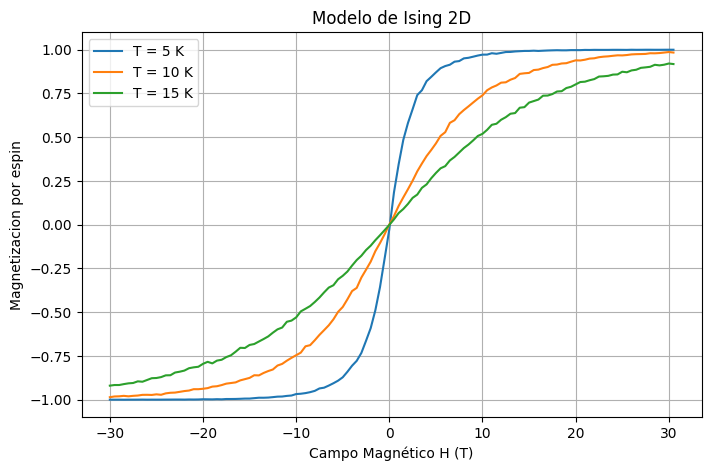

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Constantes del sistema
k_B = 1.380649e-23
mu_B = 9.2740100783e-24
C = mu_B / k_B
J = 1.0  # Acoplamiento

# Parametros de simulacion
n = 10  # Red de 10x10
MC_steps = 200
temperaturas = [5, 10, 15]
campos_H = np.arange(-30, 31, 0.5)

# Semilla aleatoria
np.random.seed(42)

# Estado inicial de la red
red = np.random.choice([-1, 1], size=(n, n))

# Guardar resultados
resultados = []

# Iterar sobre T y H
for T in temperaturas:
    for H in campos_H:
        # Acumulador de magnetizacion
        Mag_acumulada = 0

        # Pasos de Monte Carlo
        for m in range(MC_steps):
            # Recorrer todos los sitios de la red
            for i in range(n):
                for j in range(n):
                    # Valor del espin actual
                    s = red[i, j]

                    # Suma de los 4 primeros vecinos
                    vecinos = (red[(i + 1) % n, j] +
                               red[(i - 1) % n, j] +
                               red[i, (j + 1) % n] +
                               red[i, (j - 1) % n])

                    # Diferencia de energia delta E
                    deltaE = 2 * s * (J * vecinos + C * H)

                    # Criterio de Metropolis
                    if deltaE <= 0:
                        red[i, j] = -s
                    else:
                        prob = np.exp(-deltaE / T)
                        if np.random.rand() < prob:
                            red[i, j] = -s

                    # Acumular magnetizacion actual
                    Mag_acumulada += red[i, j]

        # Magnetizacion promedio por espin
        Mag_media = Mag_acumulada / (MC_steps * n * n)
        resultados.append([T, H, Mag_media])

# Crear DataFrame con los resultados
df = pd.DataFrame(resultados, columns=['T', 'H', 'Magnetizacion'])

# Graficar magnetizacion vs campo H
plt.figure(figsize=(8, 5))
for T in temperaturas:
    datos = df[df['T'] == T]
    plt.plot(datos['H'], datos['Magnetizacion'], label=f'T = {T} K')

plt.xlabel('Campo Magnético H (T)')
plt.ylabel('Magnetizacion por espin')
plt.title('Modelo de Ising 2D')
plt.legend()
plt.grid(True)
plt.show()